# Appendix C | Worked solutions

*Stable Numerical Computation*

Stable formulas preserve useful answers even when an intermediate probability underflows. Separate the information lost when inputs are stored from the error introduced by subsequent arithmetic; a wider accumulator can address only the latter.

Eight exercises progress from tracing small calculations to diagnosing implementation errors. These are controlled numerical examples, not performance or model-quality benchmarks.

## Setup

Run all cells in order from anywhere inside the companion repository. The written PDF contains every problem, explanation, and plot; the notebook PDF adds the code and saved outputs. NumPy and Matplotlib are required; Appendix C also uses PyTorch. No downloads, credentials, GPU, or trained checkpoint are needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch04_attention/attention.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
plt.rcdefaults()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
import torch
from examples.ch04_attention.attention import stable_softmax
from examples.ch08_modern.model import rms_norm

def logit_loss(logits, target):
    shifted=np.asarray(logits,dtype=np.float64)-np.max(logits)
    return np.log(np.exp(shifted).sum())-shifted[target]


## 1. Compare representable gaps

**Problem.** Under round-to-nearest, what happens to $1+2^{-8}$ in FP16 and in BF16 with ties to even?

**Solution.** The offset $2^{-8}=1/256$ equals four FP16 gaps of $1/1024$, so FP16 represents it exactly: 1.00390625. A BF16 gap at 1 is $1/128$, so the number is exactly halfway between 1 and $1+1/128$. The lower endpoint has an even last significand bit, so ties-to-even chooses 1. More exponent range does not imply more precision near one.

Original: 1.00390625 FP16: 1.00390625 BF16: 1.0


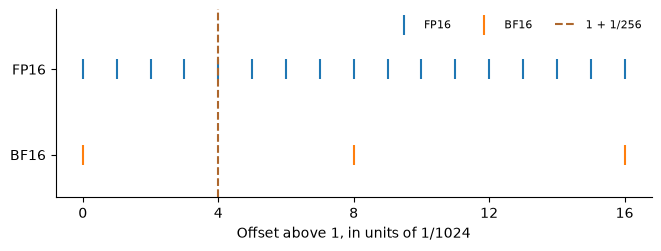

In [2]:
value=1+2**-8
fp16=np.float16(value)
bf16=torch.tensor(value,dtype=torch.bfloat16).float().item()
assert float(fp16)==value and bf16==1.
print("Original:",value,"FP16:",float(fp16),"BF16:",bf16)
fig,ax=plt.subplots(figsize=(6.5,2.4),layout="constrained")
for row,step,name in [(1,1,"FP16"),(0,8,"BF16")]:
    marks=np.arange(0,17,step)
    ax.scatter(marks,np.full_like(marks,row),marker="|",s=200,label=name)
ax.axvline(4,color="#ad672d",linestyle="--",label="1 + 1/256")
ax.set(yticks=[0,1],yticklabels=["BF16","FP16"],ylim=(-.5,1.7),
       xticks=[0,4,8,12,16],xlabel="Offset above 1, in units of 1/1024")
ax.legend(loc="upper right",frameon=False,ncol=3,fontsize=8);plt.show()

## 2. Shift before exponentiating

**Problem.** For logits $(1000,1000+\log2,1000+\log5)$, give shifted exponentials, probabilities, and the middle-class loss.

**Solution.** The maximum is $1000+\log5$. Subtracting it yields exponentials $(1/5,2/5,1)$ with sum $8/5$. The probabilities are $(1/8,2/8,5/8)$. The middle-class loss is $-\log(2/8)=\log4$, approximately 1.386294. Subtracting a shared offset preserves differences and avoids overflowing the exponentials.

In [3]:
z=1000+np.log([1.,2.,5.]);exponentials=np.exp(z-z.max())
p=stable_softmax(z);loss=logit_loss(z,1)
np.testing.assert_allclose(exponentials,[.2,.4,1.],atol=1e-13)
np.testing.assert_allclose(p,[.125,.25,.625],atol=1e-13)
np.testing.assert_allclose(loss,np.log(4),atol=1e-13)
print("Shifted exponentials:",exponentials,"Probabilities:",p)
print("Middle-class loss:",loss)

Shifted exponentials: [0.2 0.4 1. ] Probabilities: [0.125 0.25  0.625]
Middle-class loss: 1.3862943611199603


## 3. Normalize only permitted keys

**Problem.** Normalize scores $(4,1,3)$ with only the last two keys allowed. Then remove every allowed key. What does the canonical attention routine specify?

**Solution.** The excluded score 4 does not participate in either the maximum or denominator. The permitted maximum is 3, so shifted contributions are $(0,e^{-2},1)$. Weights are $(0,1/(1+e^2),e^2/(1+e^2))$, approximately $(0,0.119203,0.880797)$. An entirely masked row raises ValueError in the book implementation. It does not claim that an empty set defines a probability distribution.

In [4]:
scores=np.array([4.,1.,3.])
p=stable_softmax(scores,[False,True,True])
np.testing.assert_allclose(p,[0,1/(1+np.exp(2)),np.exp(2)/(1+np.exp(2))])
assert p[0]==0;np.testing.assert_allclose(p.sum(),1)
try:
    stable_softmax(scores,[False,False,False])
except ValueError:
    empty_policy="ValueError, as specified"
else:
    raise AssertionError("An empty row should be rejected")
print("Allowed-key weights:",p,"Empty-row behavior:",empty_policy)

Allowed-key weights: [0.       0.119203 0.880797] Empty-row behavior: ValueError, as specified


## 4. Audit low-precision normalization

**Problem.** A proposed RMSNorm uses FP16 inputs, squares, and output. Choose a small input, a high-precision reference, and intermediates to inspect. What should change if squares become zero?

**Solution.** Use $(10^{-4},-10^{-4})$, unit gains, and epsilon $10^{-6}$. First inspect the actual stored inputs, then their squares, mean square, denominator, normalized values, and output conversion. The FP16 squares round to zero, losing a mean square near $10^{-8}$. Cast inputs before squaring and accumulate in FP32. For an arithmetic check, form the float64 reference from the stored inputs rather than the original decimal values. The canonical implementation does this wider calculation and then rounds its output back to the input dtype. A small explicit tolerance covers that final rounding.

In [5]:
x=torch.tensor([1e-4,-1e-4],dtype=torch.float16)
low_squares=x.square()
wide_squares=x.float().square()
stored=x.double().numpy()
reference=stored/np.sqrt(np.mean(stored**2)+1e-6)
actual=rms_norm(x,torch.ones(2),eps=1e-6).float().numpy()
assert torch.all(low_squares==0) and torch.all(wide_squares>0)
np.testing.assert_allclose(actual,reference,atol=5e-5,rtol=5e-4)
print("Stored input:",stored)
print("FP16 squares:",low_squares.float().numpy())
print("FP32 squares:",[float(t) for t in wide_squares])
print("Reference:",reference,"Canonical output:",actual)

Stored input: [ 0.0001 -0.0001]
FP16 squares: [0. 0.]
FP32 squares: [1.000331906197971e-08, 1.000331906197971e-08]
Reference: [ 0.09952 -0.09952] Canonical output: [ 0.099548 -0.099548]


## 5. Keep the log loss finite

**Problem.** For logits $(0,-1000)$ and the second class as target, compare the rounded probability with the stable loss. Add 2000 to both logits and repeat.

**Solution.** The exponential of $-1000$ underflows to zero in float64, so the stored target probability is zero. Taking its logarithm would give negative infinity and an infinite loss. Directly from logits, the loss is $\log(1+e^{-1000})+1000$, which rounds to 1000. After the common shift, logits $(2000,1000)$ have exactly the same difference and the same stable loss. This avoids a damaging intermediate computation rather than changing the mathematical objective.

Rounded target probability: 0.0 Stable loss: 1000.0


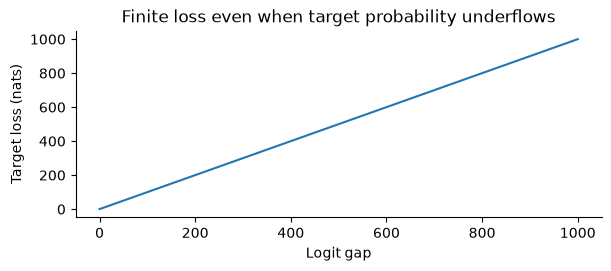

In [6]:
z=np.array([0.,-1000.])
p=stable_softmax(z);loss=logit_loss(z,1)
assert p[1]==0 and loss==1000
assert logit_loss(z+2000,1)==loss
print("Rounded target probability:",p[1],"Stable loss:",loss)
gap=np.linspace(0,1000,501)
losses=np.logaddexp(0,-gap)+gap
fig,ax=plt.subplots(figsize=(6,2.6),layout="constrained")
ax.plot(gap,losses)
ax.set(xlabel="Logit gap",ylabel="Target loss (nats)",
       title="Finite loss even when target probability underflows")
plt.show()

## 6. Locate lost input information

**Problem.** Store logits $(1024,1024.25)$ in FP16. Compare softmax on the original float64 values, float64 on the stored values, and low-precision computation. Which discrepancy can a wider accumulator fix?

**Solution.** At 1024 the FP16 gap is 1, so both stored logits become 1024. Their float64 softmax is therefore $(0.5,0.5)$, as is the low-precision result. The original logits give approximately $(0.4378235,0.5621765)$. That discrepancy is input quantization error: the difference 0.25 has already disappeared. A wider accumulator can reduce later arithmetic error but cannot infer the lost logit difference. Here the computation on the stored values is exact, so no accumulator improvement can restore the original probabilities.

In [7]:
original=np.array([1024.,1024.25])
stored=original.astype(np.float16)
original_reference=stable_softmax(original)
stored_reference=stable_softmax(stored.astype(np.float64))
low=np.exp(stored-stored.max());low/=low.sum()
np.testing.assert_array_equal(stored,[1024,1024])
np.testing.assert_allclose(stored_reference,[.5,.5])
np.testing.assert_allclose(low,stored_reference)
assert not np.allclose(original_reference,stored_reference)
print("Stored logits:",stored)
print("Original-input reference:",original_reference)
print("Stored-input reference:",stored_reference,"FP16:",low)

Stored logits: [1.024e+03 1.024e+03]
Original-input reference: [0.437823 0.562177]
Stored-input reference: [0.5 0.5] FP16: [0.5 0.5]


## 7. Place epsilon deliberately

**Problem.** Normalize $(10^{-4},-10^{-4})$ with epsilon $10^{-6}$ inside and outside the root. Check zero inputs. Why is the zero test insufficient?

**Solution.** The mean square is $q=10^{-8}$. The inside-root denominator is $\sqrt{1.01\times10^{-6}}\approx0.00100499$, giving magnitudes about 0.0995037. The outside-root denominator is $\sqrt{10^{-8}}+10^{-6}=0.000101$, giving about 0.990099. Both return zeros on zero inputs because both denominators are positive. Passing that one boundary test does not make the two functions equivalent; small nonzero inputs expose their different scaling.

In [8]:
x=np.array([1e-4,-1e-4]);eps=1e-6
inside=lambda x: x/np.sqrt(np.mean(x*x)+eps)
outside=lambda x: x/(np.sqrt(np.mean(x*x))+eps)
np.testing.assert_allclose(inside(x),[.099503719,-.099503719],atol=1e-9)
np.testing.assert_allclose(outside(x),[.99009901,-.99009901],atol=1e-9)
assert np.all(inside(np.zeros(2))==0)
assert np.all(outside(np.zeros(2))==0)
print("Epsilon inside root:",inside(x))
print("Epsilon outside root:",outside(x))
print("Both return zeros on a zero input.")

Epsilon inside root: [ 0.099504 -0.099504]
Epsilon outside root: [ 0.990099 -0.990099]
Both return zeros on a zero input.


## 8. Use absolute and relative tolerances

**Problem.** Reference values $(0,10^{-8},1000)$ are compared with $(10^{-9},1.1\times10^{-8},1000.01)$ using atol $2\times10^{-9}$ and rtol $2\times10^{-5}$. Evaluate combined, absolute-only, and relative-only checks; check NaNs separately.

**Solution.** Absolute errors are approximately $(10^{-9},10^{-9},0.01)$. Combined allowances are $(2\times10^{-9},2.0002\times10^{-9},0.020000002)$, so all pass. Absolute-only tolerances pass the first two but fail the last. Relative-only tolerances have allowances $(0,2\times10^{-13},0.02)$, so the first two fail and the last passes. The absolute term protects small reference values. Check finiteness before comparing errors; never treat NaNs as valid matching values merely to make a test pass.

In [9]:
reference=np.array([0.,1e-8,1000.])
computed=np.array([1e-9,1.1e-8,1000.01])
atol,rtol=2e-9,2e-5
assert np.isfinite(reference).all() and np.isfinite(computed).all()
error=np.abs(computed-reference)
combined=error<=atol+rtol*np.abs(reference)
absolute=error<=atol;relative=error<=rtol*np.abs(reference)
assert combined.all()
np.testing.assert_array_equal(absolute,[True,True,False])
np.testing.assert_array_equal(relative,[False,False,True])
assert not np.isfinite(np.array([np.nan])).all()
for label,values in [("Combined",combined),("Absolute only",absolute),
                     ("Relative only",relative)]:
    print(label,values)

Combined [ True  True  True]
Absolute only [ True  True False]
Relative only [False False  True]
